# Bird's Eye View with Waymo Open Dataset

# Install Requirements

In [4]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install --upgrade pip

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 7.5 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 23.0.1
    Uninstalling pip-23.0.1:
      Successfully uninstalled pip-23.0.1
Note: you may need to restart the kernel to use updated packages.


# BEV Implement

In [117]:
import cv2
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image


## Load Waymo Dataset

In [118]:
from torch_waymo import WaymoDataset


dataset_path = '/home/nataniel/Desktop/work2/aiea/challenge_team/data'
train_dataset = WaymoDataset(dataset_path, 'training')

resolutions = []
pixel_ranges = []
data_types = []
timestamps = []
camera_counts = []
all_camera_names = set()

In [119]:
frame = train_dataset[0] # Load the first frame of one video sequence

In [120]:
print("Number of camera calibrations:",
      len(frame.context.camera_calibrations))

for calib in frame.context.camera_calibrations:
      print("Camera name:", calib.name)
      print("Intrinsic length:", len(calib.intrinsic))
      print("Intrinsic:", calib.intrinsic[:4])
      print("Extrinsic shape:", np.array(calib.extrinsic).shape)
      print("Width x Height:", calib.width, calib.height)
      print("----")

    

Number of camera calibrations: 5
Camera name: 1
Intrinsic length: 9
Intrinsic: [2059.612011552946, 2059.612011552946, 952.4121898799498, 634.5872082485005]
Extrinsic shape: (4, 4)
Width x Height: 1920 1280
----
Camera name: 2
Intrinsic length: 9
Intrinsic: [2046.6346113297673, 2046.6346113297673, 975.056043638034, 640.9087071643551]
Extrinsic shape: (4, 4)
Width x Height: 1920 1280
----
Camera name: 3
Intrinsic length: 9
Intrinsic: [2053.547383468203, 2053.547383468203, 944.359788133735, 630.6490975690649]
Extrinsic shape: (4, 4)
Width x Height: 1920 1280
----
Camera name: 4
Intrinsic length: 9
Intrinsic: [2050.2525380004945, 2050.2525380004945, 970.3085586719832, 248.13553724409144]
Extrinsic shape: (4, 4)
Width x Height: 1920 886
----
Camera name: 5
Intrinsic length: 9
Intrinsic: [2053.6156009850306, 2053.6156009850306, 970.5469368931234, 235.61579209679962]
Extrinsic shape: (4, 4)
Width x Height: 1920 886
----


In [ ]:
from torch_waymo.protocol.dataset_proto import CameraName

front_calib = None

for c in frame.context.camera_calibrations:
    if c.name == CameraName.FRONT:
        front_calib = c
        break

assert front_calib is not None, "FRONT calibration not found"

print("Found FRONT calibration")

K_raw = front_calib.intrinsic
T_cam_to_vehicle = front_calib.extrinsic

Found FRONT calibration


In [122]:
fx, fy, cx, cy = front_calib.intrinsic[:4]

K = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0, 0, 1]
], dtype=np.float32)

In [123]:
import io
from PIL import Image
import numpy as np

def decode_image(camera_image):
    img = Image.open(io.BytesIO(camera_image.image)).convert("RGB")
    return np.array(img)

In [124]:
T = front_calib.extrinsic
print(np.linalg.det(T[:3,:3]))

1.0


## Implement ResNet 18

In [125]:
%pip install torch torchvision matplotlib -q

Note: you may need to restart the kernel to use updated packages.


In [126]:
import torch
import torch.nn as nn
import torchvision.models as models

In [127]:
class ResNet18Backbone(nn.Module):
    def __init__(self, out_channels=64, pretrained=True):
        super().__init__()

        # Load pretrained model
        if pretrained:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            resnet = models.resnet18(weights=weights)
        else:
            resnet = models.resnet18(weights=None)

        # Keep layers up to layer3 (stride 8 total)
        self.stem = nn.Sequential(
            resnet.conv1,   # stride 2
            resnet.bn1,
            resnet.relu,
            resnet.maxpool  # stride 2
        )

        self.layer1 = resnet.layer1  # stride 1
        self.layer2 = resnet.layer2  # stride 2
        self.layer3 = resnet.layer3  # stride 2

        # Channel reduction (256 → out_channels)
        self.reduce = nn.Conv2d(256, out_channels, kernel_size=1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.reduce(x)
        return x

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ResNet18Backbone(out_channels=64)
# model = model.to(device)
model.eval()

x = torch.randn(1, 3, 640, 960)
with torch.no_grad():
    y = model(x)

print(y.shape)

torch.Size([1, 64, 40, 60])


In [129]:
for param in model.stem.parameters():
    param.requires_grad = False

In [130]:
import torchvision.transforms as T

transform = T.Compose([
    T.Resize((640, 960)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [131]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

x = x.to(device)

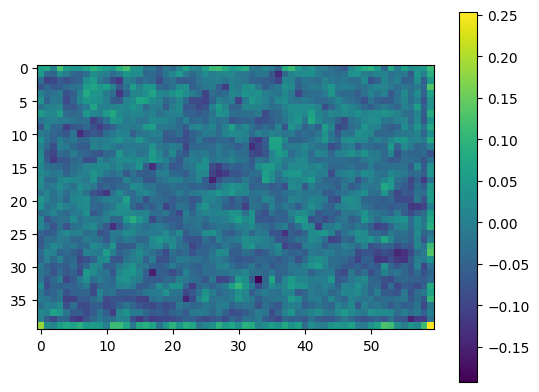

In [132]:
import matplotlib.pyplot as plt

feature_map = y[0, 0].cpu().numpy()
plt.imshow(feature_map)
plt.colorbar()
plt.show()

In [133]:
import torch

def create_depth_bins(d_min=1.0, d_max=50.0, num_bins=80, device="cpu"):
    depth_bins = torch.logspace(
        torch.log10(torch.tensor(d_min)),
        torch.log10(torch.tensor(d_max)),
        steps=num_bins,
        device=device
    )
    return depth_bins

In [134]:
depth_bins = create_depth_bins()
print(depth_bins.shape)

torch.Size([80])


In [135]:
class DepthHead(nn.Module):
    def __init__(self, in_channels=64, num_bins=80):
        super().__init__()

        self.depth_conv = nn.Conv2d(
            in_channels,
            num_bins,
            kernel_size=1
        )

    def forward(self, x):
        # x: (B, C, H, W)
        depth_logits = self.depth_conv(x)  # (B, D, H, W)

        depth_probs = torch.softmax(depth_logits, dim=1)

        return depth_probs

In [136]:
class ImageEncoder(nn.Module):
    def __init__(self, out_channels=64, num_bins=80):
        super().__init__()

        self.backbone = ResNet18Backbone(out_channels)
        self.depth_head = DepthHead(out_channels, num_bins)

    def forward(self, x):
        features = self.backbone(x)          # (B, 64, Hf, Wf)
        depth_probs = self.depth_head(features)  # (B, D, Hf, Wf)

        return features, depth_probs

In [137]:
model = ImageEncoder()
model.eval()

x = torch.randn(1, 3, 640, 960)

with torch.no_grad():
    features, depth_probs = model(x)

print("Features:", features.shape)
print("Depth probs:", depth_probs.shape)

Features: torch.Size([1, 64, 40, 60])
Depth probs: torch.Size([1, 80, 40, 60])


In [138]:
print(y.shape)

torch.Size([1, 64, 40, 60])


In [139]:
h = depth_probs.shape[2]
w = depth_probs.shape[3]

print(depth_probs.sum(dim=1)[0, h//2, w//2])

tensor(1.0000)


In [140]:
def lift(features, depth_probs):
    """
    features: (B, C, H, W)
    depth_probs: (B, D, H, W)
    returns: (B, C, D, H, W)
    """
    B, C, H, W = features.shape
    D = depth_probs.shape[1]

    # Expand feature map along depth dimension
    features = features.unsqueeze(2)         # (B, C, 1, H, W)
    depth_probs = depth_probs.unsqueeze(1)   # (B, 1, D, H, W)

    frustum = features * depth_probs         # (B, C, D, H, W)

    return frustum

In [141]:
frustum = lift(features, depth_probs)

print("Frustum shape:", frustum.shape)

Frustum shape: torch.Size([1, 64, 80, 40, 60])


In [142]:
recovered = frustum.sum(dim=2)

print(torch.allclose(recovered, features.squeeze(2), atol=1e-5))

True


Pixel Coordinate Grid

In [143]:
def create_pixel_grid(Hf, Wf, stride, device):
    """
    Returns:
        grid: (1, Hf, Wf, 3) homogeneous pixel coords
    """
    ys, xs = torch.meshgrid(
        torch.arange(Hf, device=device),
        torch.arange(Wf, device=device),
        indexing='ij'
    )

    xs = xs.float() * stride
    ys = ys.float() * stride

    ones = torch.ones_like(xs)

    grid = torch.stack([xs, ys, ones], dim=-1)  # (Hf, Wf, 3)

    return grid.unsqueeze(0)  # (1, Hf, Wf, 3)

In [144]:
grid = create_pixel_grid(40, 60, stride=16, device=features.device)
print(grid.shape)

torch.Size([1, 40, 60, 3])


In [145]:
def backproject(depth_bins, K, pixel_grid):
    """
    depth_bins: (D,)
    K: (B, 3, 3)
    pixel_grid: (1, Hf, Wf, 3)

    returns:
        cam_points: (B, D, Hf, Wf, 3)
    """

    B = K.shape[0]
    D = depth_bins.shape[0]
    Hf, Wf = pixel_grid.shape[1:3]

    K_inv = torch.inverse(K)  # (B,3,3)

    # Expand pixel grid
    pixel_grid = pixel_grid.expand(B, -1, -1, -1)  # (B,Hf,Wf,3)
    pixel_grid = pixel_grid.reshape(B, -1, 3)      # (B,Hf*Wf,3)

    # Apply K inverse
    cam_dirs = torch.bmm(K_inv, pixel_grid.permute(0,2,1))  # (B,3,Hf*Wf)
    cam_dirs = cam_dirs.permute(0,2,1)  # (B,Hf*Wf,3)

    # Expand depth bins
    depth = depth_bins.view(1, D, 1, 1, 1)

    cam_dirs = cam_dirs.view(B, 1, Hf, Wf, 3)

    cam_points = cam_dirs * depth  # (B,D,Hf,Wf,3)

    return cam_points

In [146]:
print("K shape:", K.shape)
print("depth_bins shape:", depth_bins.shape)
print("grid shape:", grid.shape)

K shape: (3, 3)
depth_bins shape: torch.Size([80])
grid shape: torch.Size([1, 40, 60, 3])


In [147]:
cam_points = backproject(depth_bins, K, grid)
print(cam_points.shape)

TypeError: inverse(): argument 'input' (position 1) must be Tensor, not numpy.ndarray

In [ ]:
T_cam_to_vehicle = T_cam_to_vehicle.squeeze()
T_cam_to_vehicle = T_cam_to_vehicle.view(1,4,4)
print("T shape:", T_cam_to_vehicle.shape)

T shape: torch.Size([1, 4, 4])


In [ ]:
def transform_to_vehicle(cam_points, T):
    """
    cam_points: (B,D,Hf,Wf,3)
    T: (B,4,4)
    returns: (B,D,Hf,Wf,3)
    """

    B, D, Hf, Wf, _ = cam_points.shape

    ones = torch.ones_like(cam_points[..., :1])
    hom_points = torch.cat([cam_points, ones], dim=-1)  # (B,D,Hf,Wf,4)

    hom_points = hom_points.view(B, -1, 4).permute(0,2,1)  # (B,4,N)

    veh_points = torch.bmm(T, hom_points)  # (B,4,N)

    veh_points = veh_points.permute(0,2,1)[..., :3]
    veh_points = veh_points.view(B, D, Hf, Wf, 3)

    return veh_points

In [ ]:
veh_points = transform_to_vehicle(cam_points, T_cam_to_vehicle)
print(veh_points.shape)

torch.Size([1, 80, 40, 60, 3])


In [ ]:
def transform_to_world(veh_points, pose):
    B, D, Hf, Wf, _ = veh_points.shape

    ones = torch.ones_like(veh_points[..., :1])
    hom = torch.cat([veh_points, ones], dim=-1)

    hom = hom.view(B, -1, 4).permute(0,2,1)

    world = torch.bmm(pose, hom)

    world = world.permute(0,2,1)[..., :3]
    world = world.view(B, D, Hf, Wf, 3)

    return world

In [ ]:
pose = torch.tensor(frame.pose, dtype=torch.float32)
pose = pose.unsqueeze(0).to(veh_points.device)  # (1,4,4)

if 'T0' not in globals():
    T0 = pose.clone()
    T0_inv = torch.inverse(T0)

world_points = transform_to_world(veh_points, pose)

In [ ]:
T_relative = torch.bmm(T0_inv, pose)  # (1,4,4)

print(pose.shape)          # (1,4,4)
print(type(pose))          # torch.Tensor

torch.Size([1, 4, 4])
<class 'torch.Tensor'>


In [ ]:
# ---- GROUP 3: Transform to Reference Frame ----

def transform_points(points, T):
    B, D, Hf, Wf, _ = points.shape

    ones = torch.ones_like(points[..., :1])
    hom = torch.cat([points, ones], dim=-1)  # (B,D,Hf,Wf,4)

    hom = hom.view(B, -1, 4).permute(0,2,1)  # (B,4,N)

    out = torch.bmm(T, hom)

    out = out.permute(0,2,1)[..., :3]
    out = out.view(B, D, Hf, Wf, 3)

    return out

ref_points = transform_points(veh_points, T_relative)

In [ ]:
x_min, x_max = -50.0, 50.0
y_min, y_max = -50.0, 50.0
resolution = 0.5

bev_H = int((x_max - x_min) / resolution)  # 200
bev_W = int((y_max - y_min) / resolution)  # 200

In [ ]:
world_points = transform_to_world(veh_points, pose)
print(world_points.shape)

torch.Size([1, 80, 40, 60, 3])


In [ ]:
# ---- GROUP 5: Projection to BEV Indices ----

def project_to_bev(points):
    x = points[..., 0]
    y = points[..., 1]

    x_idx = ((x - x_min) / resolution).long()
    y_idx = ((y - y_min) / resolution).long()

    mask = (
        (x_idx >= 0) & (x_idx < bev_H) &
        (y_idx >= 0) & (y_idx < bev_W)
    )

    return x_idx, y_idx, mask

x_idx, y_idx, mask = project_to_bev(ref_points)

In [ ]:
if 'global_bev' not in globals():
    B, C = frustum.shape[0], frustum.shape[1]
    global_bev = torch.zeros(B, C, bev_H, bev_W, device=frustum.device)

In [ ]:
def splat(frustum, x_idx, y_idx, mask, bev):
    B, C, D, Hf, Wf = frustum.shape

    for b in range(B):
        for d in range(D):
            valid = mask[b, d]

            xi = x_idx[b, d][valid]
            yi = y_idx[b, d][valid]

            feat = frustum[b, :, d][..., valid]  # (C,N)

            bev[b, :, xi, yi] += feat

    return bev

global_bev = splat(frustum, x_idx, y_idx, mask, global_bev)

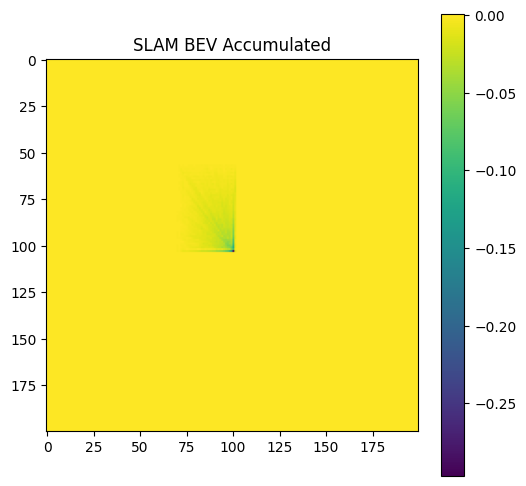

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(global_bev[0,0].detach().cpu())
plt.title("SLAM BEV Accumulated")
plt.colorbar()
plt.show()

## BEV SLAM

In [149]:
import torch
import torch.nn.functional as F
import math

In [151]:

def build_frame_bev(frustum, veh_points, resolution=0.5,
                    x_min=0.0, x_max=50.0,
                    y_min=-25.0, y_max=25.0):

    B, C, D, Hf, Wf = frustum.shape
    device = frustum.device

    bev_H = int((x_max - x_min) / resolution)
    bev_W = int((y_max - y_min) / resolution)

    bev = torch.zeros(B, C, bev_H, bev_W, device=device)

    x = veh_points[..., 0]
    y = veh_points[..., 1]

    x_idx = ((x - x_min) / resolution).long()
    y_idx = ((y - y_min) / resolution).long()

    mask = (
        (x_idx >= 0) & (x_idx < bev_H) &
        (y_idx >= 0) & (y_idx < bev_W)
    )

    for b in range(B):
        for d in range(D):
            valid = mask[b, d]

            xi = x_idx[b, d][valid]
            yi = y_idx[b, d][valid]

            feat = frustum[b, :, d][..., valid]  # (C, N)

            bev[b, :, xi, yi] += feat

    return bev

In [152]:
# ---- GROUP 2: Compute Relative Pose ΔT ----

def compute_delta_pose(prev_pose, current_pose):
    """
    prev_pose, current_pose: (1,4,4)
    returns ΔT: transform from previous vehicle frame to current vehicle frame
    """
    prev_inv = torch.inverse(prev_pose)
    delta = torch.bmm(prev_inv, current_pose)
    return delta

In [153]:
# ---- GROUP 3: Extract dx, dy, yaw ----

def extract_motion(delta_pose):
    dx = delta_pose[0,0,3]
    dy = delta_pose[0,1,3]

    yaw = torch.atan2(delta_pose[0,1,0], delta_pose[0,0,0])

    return dx, dy, yaw

In [154]:
# ---- GROUP 4: Build BEV Affine Matrix ----

def build_affine(dx, dy, yaw, H, W, resolution, device):
    """
    Builds 2D affine transform for grid_sample.
    """

    # meters → pixels
    tx = dx / resolution
    ty = dy / resolution

    # Normalize pixel shift to [-1,1] for grid_sample
    tx_norm = 2 * tx / W
    ty_norm = 2 * ty / H

    cos_y = torch.cos(-yaw)
    sin_y = torch.sin(-yaw)

    theta = torch.zeros((1,2,3), device=device)

    theta[0,0,0] = cos_y
    theta[0,0,1] = -sin_y
    theta[0,1,0] = sin_y
    theta[0,1,1] = cos_y

    theta[0,0,2] = -tx_norm
    theta[0,1,2] = -ty_norm

    return theta

In [155]:
# ---- GROUP 5: Warp Previous Global BEV ----

def warp_bev(bev, theta):
    B, C, H, W = bev.shape

    grid = F.affine_grid(theta, size=bev.size(), align_corners=False)
    warped = F.grid_sample(bev, grid, align_corners=False)

    return warped

In [156]:
# ---- GROUP 6: Fuse BEV Maps ----

def fuse_maps(warped_bev, frame_bev, alpha):
    return alpha * warped_bev + (1 - alpha) * frame_bev

In [157]:
# ---- GROUP 6: Fuse BEV Maps ----

def fuse_maps(warped_bev, frame_bev, alpha):
    return alpha * warped_bev + (1 - alpha) * frame_bev

In [158]:
# ---- GROUP 7: SLAM Update ----

def slam_update(frame_bev, pose):
    global global_bev, prev_pose

    if prev_pose is None:
        global_bev = frame_bev.clone()
        prev_pose = pose.clone()
        return global_bev

    delta = compute_delta_pose(prev_pose, pose)
    dx, dy, yaw = extract_motion(delta)

    theta = build_affine(dx, dy, yaw, H, W, resolution, device)

    warped = warp_bev(global_bev, theta)

    global_bev = fuse_maps(warped, frame_bev, fusion_alpha)

    prev_pose = pose.clone()

    return global_bev

In [165]:
# ---- GROUP 1: Vectorized Frame BEV ----

def build_frame_bev(frustum, veh_points,
                    resolution=0.5,
                    x_min=0.0, x_max=50.0,
                    y_min=-25.0, y_max=25.0):

    B, C, D, Hf, Wf = frustum.shape
    device = frustum.device

    bev_H = int((x_max - x_min) / resolution)
    bev_W = int((y_max - y_min) / resolution)

    bev = torch.zeros(B, C, bev_H, bev_W, device=device)

    x = veh_points[..., 0]
    y = veh_points[..., 1]

    x_idx = ((x - x_min) / resolution).long()
    y_idx = ((y - y_min) / resolution).long()

    mask = (
        (x_idx >= 0) & (x_idx < bev_H) &
        (y_idx >= 0) & (y_idx < bev_W)
    )

    # Flatten everything
    x_idx = x_idx.view(B, -1)
    y_idx = y_idx.view(B, -1)
    mask = mask.view(B, -1)

    frustum_flat = frustum.view(B, C, -1)

    for b in range(B):
        valid = mask[b]

        xi = x_idx[b][valid]
        yi = y_idx[b][valid]

        linear_idx = xi * bev_W + yi  # flatten 2D → 1D index

        bev_flat = bev[b].view(C, -1)

        bev_flat.index_add_(
            1,
            linear_idx,
            frustum_flat[b, :, valid]
        )

    return bev

In [163]:
frame_bev = build_frame_bev(frustum, veh_points)

In [ ]:
sequence_indices = list(range(len(train_dataset)))

In [170]:
from PIL import Image

In [171]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
B, C, H, W = frame_bev.shape

global_bev = torch.zeros_like(frame_bev)
prev_pose = None

resolution = 0.5  # meters per pixel
fusion_alpha = 0.7  # temporal smoothing factor

In [ ]:

for idx in sequence_indices:

    frame = train_dataset[idx]

    # --- IMAGE ---
    img_msg = frame.images[0]  # choose FRONT camera if needed

    jpeg_bytes = img_msg.image
    img_array = np.frombuffer(jpeg_bytes, dtype=np.uint8)
    img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img)

    img_tensor = transform(img_pil).unsqueeze(0).to(device)

    # --- INTRINSICS ---
    calib = frame.context.camera_calibrations[0]

    K = torch.tensor([
        [calib.intrinsic[0], 0, calib.intrinsic[2]],
        [0, calib.intrinsic[1], calib.intrinsic[3]],
        [0, 0, 1]
    ], dtype=torch.float32).unsqueeze(0).to(device)

    # --- EXTRINSIC ---
    T_cam_to_vehicle = torch.tensor(calib.extrinsic, dtype=torch.float32)
    T_cam_to_vehicle = T_cam_to_vehicle.unsqueeze(0).to(device)

    # --- POSE ---
    pose = torch.tensor(frame.pose, dtype=torch.float32)
    pose = pose.unsqueeze(0).to(device)

    # --- FORWARD PASS ---
    features, depth_probs = model(img_tensor)

    frustum = lift(features, depth_probs)

    grid = create_pixel_grid(
        features.shape[2],
        features.shape[3],
        stride=16,
        device=device
    )

    cam_points = backproject(depth_bins, K, grid)

    veh_points = transform_to_vehicle(cam_points, T_cam_to_vehicle)

    frame_bev = build_frame_bev(frustum, veh_points)

    global_bev = slam_update(frame_bev, pose)

    visualize(global_bev)

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same